## **Business Understanding**

#### **Loading libraries**

In [164]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, precision_score, recall_score)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
import xgboost as xgb
import joblib

#### **Load data**

In [19]:
df = pd.read_excel("C:\\Users\\USER\\Documents\\Final project\\emdat_with_estimated_deaths.xlsx")

In [22]:
df.head(2)

,DisNo.,Historic,Classification Key,Disaster Group,Disaster Subgroup,Disaster Type,Disaster Subtype,External IDs,Event Name,ISO,...,"Reconstruction Costs, Adjusted ('000 US$)",Insured Damage ('000 US$),"Insured Damage, Adjusted ('000 US$)",Total Damage ('000 US$),"Total Damage, Adjusted ('000 US$)",CPI,Admin Units,GADM Admin Units,Entry Date,Last Update
0,2026-0153-KEN,No,nat-hyd-flo-flo,Natural,Hydrological,Flood,Flood (General),NaN,NaN,KEN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-03-09,2026-05-15
1,2024-0962-AGO,No,nat-bio-epi-bac,Natural,Biological,Epidemic,Bacterial disease,GLIDE:EP-2025-000013,Cholera,AGO,...,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,2025-01-17,2026-05-15


## **Data Understanding**

In [24]:
df.head(5)

,DisNo.,Historic,Classification Key,Disaster Group,Disaster Subgroup,Disaster Type,Disaster Subtype,External IDs,Event Name,ISO,...,"Reconstruction Costs, Adjusted ('000 US$)",Insured Damage ('000 US$),"Insured Damage, Adjusted ('000 US$)",Total Damage ('000 US$),"Total Damage, Adjusted ('000 US$)",CPI,Admin Units,GADM Admin Units,Entry Date,Last Update
0,2026-0153-KEN,No,nat-hyd-flo-flo,Natural,Hydrological,Flood,Flood (General),NaN,NaN,KEN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-03-09,2026-05-15
1,2024-0962-AGO,No,nat-bio-epi-bac,Natural,Biological,Epidemic,Bacterial disease,GLIDE:EP-2025-000013,Cholera,AGO,...,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,2025-01-17,2026-05-15
2,2025-9122-SOM,No,nat-cli-dro-dro,Natural,Climatological,Drought,Drought,NaN,NaN,SOM,...,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,2025-02-26,2026-05-15
3,2026-0310-COD,No,nat-hyd-flo-flo,Natural,Hydrological,Flood,Flood (General),NaN,NaN,COD,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-05-05,2026-05-20
4,2025-0694-SOM,No,nat-bio-epi-bac,Natural,Biological,Epidemic,Bacterial disease,GLIDE:EP-2025-000142,Diphteria,SOM,...,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,2025-08-20,2026-06-10


In [23]:
df.dtypes

DisNo.                                           str
Historic                                         str
Classification Key                               str
Disaster Group                                   str
Disaster Subgroup                                str
Disaster Type                                    str
Disaster Subtype                                 str
External IDs                                     str
Event Name                                       str
ISO                                              str
Country                                          str
Subregion                                        str
Region                                           str
Location                                         str
Origin                                           str
Associated Types                                 str
OFDA/BHA Response                                str
Appeal                                           str
Declaration                                   

In [25]:
df.shape

(2279, 50)

In [26]:
df.isna().sum()

DisNo.                                          0
Historic                                        0
Classification Key                              0
Disaster Group                                  0
Disaster Subgroup                               0
Disaster Type                                   0
Disaster Subtype                                0
External IDs                                 1443
Event Name                                   1586
ISO                                             0
Country                                         0
Subregion                                       0
Region                                          0
Location                                      103
Origin                                       1287
Associated Types                             1768
OFDA/BHA Response                               0
Appeal                                          0
Declaration                                     0
AID Contribution ('000 US$)                  2184


In [166]:
columns_to_drop = [
    'DisNo.',
    'External IDs',
    'Event Name',
    'Entry Date',
    'Last Update',
    'Classification Key',
    'Disaster Group',
    'Disaster Subgroup',
    'Disaster Subtype',
    'Origin',
    'Associated Types',
    "AID Contribution ('000 US$)",
    'Magnitude',
    'Latitude',
    'Longitude',
    'River Basin',
    'No. Injured',
    'No. Homeless',
    "Reconstruction Costs ('000 US$)",
    "Reconstruction Costs, Adjusted ('000 US$)",
    "Insured Damage ('000 US$)",
    "Insured Damage, Adjusted ('000 US$)",
    "Total Damage ('000 US$)",
    "Total Damage, Adjusted ('000 US$)",
    "DisNo.",
    
    "End Day",
    "End Month",
    "Deaths Is Estimated",
    "Deaths Estimate Method",
    "Total Deaths",
    "Magnitude Scale"   
]

In [167]:
df_2=df.drop(columns=columns_to_drop)
print(f"Original columns: {df.shape[1]}")
print(f"Cleaned columns:  {df_2.shape[1]}")

Original columns: 50
Cleaned columns:  20


In [168]:
df_2.isnull().sum()

Historic               0
Disaster Type          0
ISO                    0
Country                0
Subregion              0
Region                 0
Location             103
OFDA/BHA Response      0
Appeal                 0
Declaration            0
Start Year             0
Start Month           50
Start Day            630
End Year               0
Estimated Deaths       0
No. Affected         600
Total Affected       194
CPI                   35
Admin Units          883
GADM Admin Units     964
dtype: int64

In [169]:
df_2.head(5)

,Historic,Disaster Type,ISO,Country,Subregion,Region,Location,OFDA/BHA Response,Appeal,Declaration,Start Year,Start Month,Start Day,End Year,Estimated Deaths,No. Affected,Total Affected,CPI,Admin Units,GADM Admin Units
0,No,Flood,KEN,Kenya,Sub-Saharan Africa,Africa,"Mombasa, Kwale, Kilifi, Tana River, Lamu, Tait...",No,No,No,2026,3.0,6.0,2026,59,NaN,27.0,NaN,NaN,NaN
1,No,Epidemic,AGO,Angola,Sub-Saharan Africa,Africa,Cacuaco (Luanda province); Bengo; Icolo e Beng...,No,No,No,2025,1.0,7.0,2025,776,NaN,27728.0,100.0,NaN,NaN
2,No,Drought,SOM,Somalia,Sub-Saharan Africa,Africa,"Gedo, Hiran, Bay, Bakool, Mudug, Bari, Toghdhe...",No,No,Yes,2025,1.0,NaN,2026,58,6500000.0,6500000.0,100.0,NaN,NaN
3,No,Flood,COD,Democratic Republic of the Congo,Sub-Saharan Africa,Africa,"Maniema, Uvira (South Kivu province)",No,No,No,2026,5.0,1.0,2026,6,79000.0,79000.0,NaN,NaN,NaN
4,No,Epidemic,SOM,Somalia,Sub-Saharan Africa,Africa,Daynile and Harmaweyne (Banadir); Galkayo and ...,No,No,No,2025,NaN,NaN,2026,89,NaN,1811.0,100.0,NaN,NaN


In [170]:
df_2.columns

Index(['Historic', 'Disaster Type', 'ISO', 'Country', 'Subregion', 'Region',
       'Location', 'OFDA/BHA Response', 'Appeal', 'Declaration', 'Start Year',
       'Start Month', 'Start Day', 'End Year', 'Estimated Deaths',
       'No. Affected', 'Total Affected', 'CPI', 'Admin Units',
       'GADM Admin Units'],
      dtype='str')

#### **Univariate Analysis**

In [124]:
df_2["Disaster Type"].value_counts()

Disaster Type
Flood                  1030
Epidemic                616
Storm                   261
Drought                 179
Mass movement (wet)      74
Earthquake               34
Wildfire                 33
Infestation              22
Extreme temperature      17
Volcanic activity        10
Mass movement (dry)       2
Animal incident           1
Name: count, dtype: int64

In [130]:
disaster_counts = df_2["Disaster Type"].value_counts()

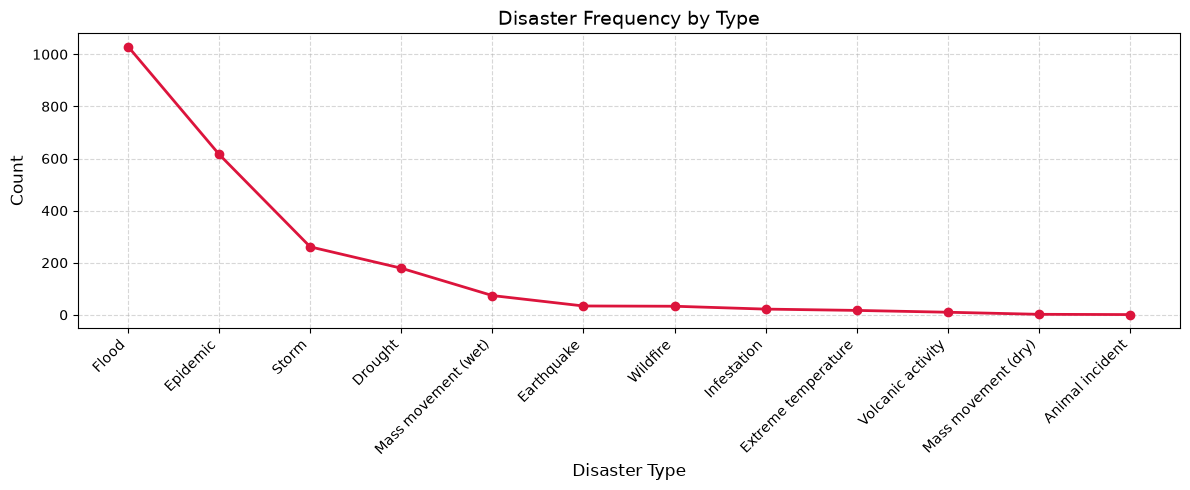

In [129]:
plt.figure(figsize=(12, 5))
plt.plot(disaster_counts.index, disaster_counts.values, marker='o', color='crimson', linewidth=2)

plt.title('Disaster Frequency by Type', fontsize=14)
plt.xlabel('Disaster Type', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

##### **Insights on disaster types**
The  analysis of disaster types shows that floods are the most frequently recorded disasters, with 1,030 cases, followed by epidemics with 616 cases and storms with 261 cases. Droughts account for 179 cases, while wet mass movements account for 74 cases. Earthquakes and wildfires have 34 and 33 cases, respectively. Infestations, extreme temperatures, volcanic activity, dry mass movements, and animal incidents are less common, with 22, 17, 10, 2, and 1 cases, respectively.

Overall, the analysis indicates that floods and epidemics dominate the dataset, suggesting that these disaster types account for a substantial proportion of recorded events. Understanding their frequency can help identify disaster patterns and inform disaster preparedness and resource allocation.

#### **Bivariate Analysis**

In [131]:
df_2.columns

Index(['Historic', 'Disaster Type', 'ISO', 'Subregion', 'Region', 'Location',
       'OFDA/BHA Response', 'Appeal', 'Declaration', 'Start Year',
       'Start Month', 'Start Day', 'End Year', 'Estimated Deaths',
       'No. Affected', 'Total Affected', 'CPI', 'Admin Units',
       'GADM Admin Units'],
      dtype='str')

In [132]:
df_2["Estimated Deaths"].value_counts()

Estimated Deaths
8       204
14      125
58      112
13      103
1        87
       ... 
249       1
2287      1
145       1
384       1
1166      1
Name: count, Length: 267, dtype: int64

In [146]:

disaster_deaths = df_2.groupby("Disaster Type")["Estimated Deaths"].sum().reset_index()
disaster_deaths = disaster_deaths.sort_values(by="Estimated Deaths", ascending=True)
print(disaster_deaths)

          Disaster Type  Estimated Deaths
0       Animal incident                12
7   Mass movement (dry)               114
10    Volcanic activity               264
6           Infestation               352
4   Extreme temperature               416
11             Wildfire               604
8   Mass movement (wet)              4235
2            Earthquake              7593
9                 Storm             20606
1               Drought             31204
5                 Flood             31944
3              Epidemic            102580


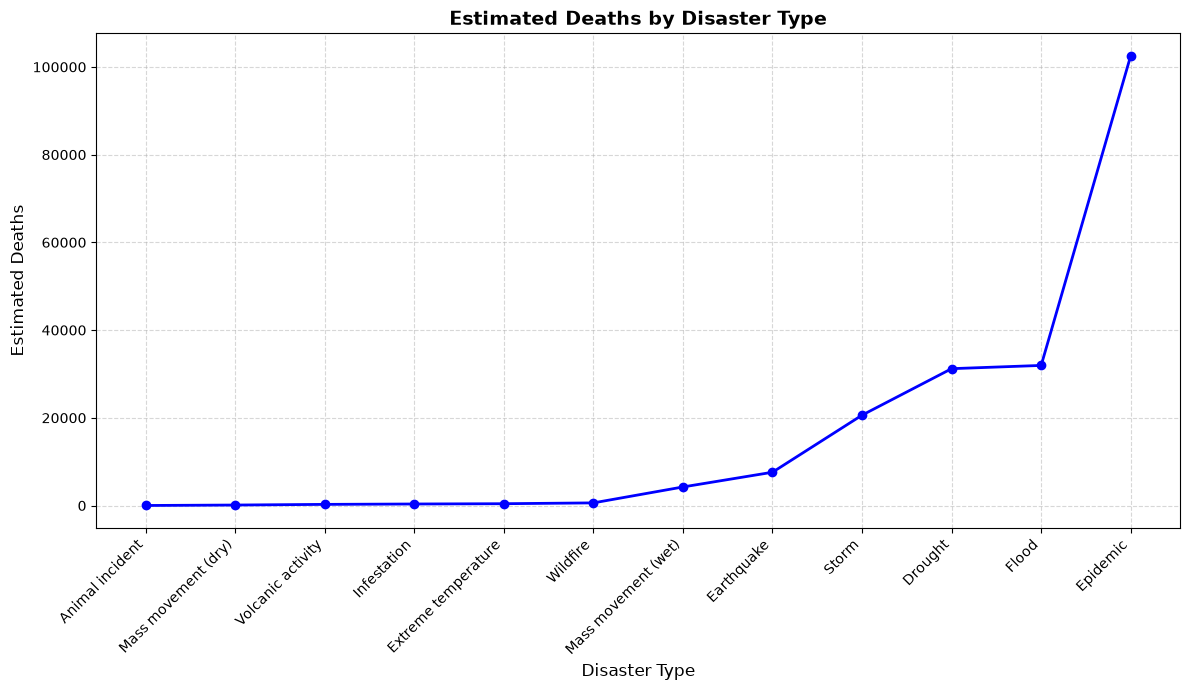

In [150]:
plt.figure(figsize=(12, 7))
plt.plot(
    disaster_deaths["Disaster Type"],
    disaster_deaths["Estimated Deaths"],
    marker="o",
    linewidth=2,
    color="blue",
)

plt.title("Estimated Deaths by Disaster Type", fontsize=14, fontweight="bold")
plt.xlabel("Disaster Type", fontsize=12)
plt.ylabel("Estimated Deaths", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

##### **Insights**
- Epidemics account for the highest total estimated fatalities with 102,580 deaths. 
- Floods (31,944 deaths) and Droughts (31,204 deaths) represent the second and third most fatal categories
- Storms (20,606 deaths) and Earthquakes (7,593 deaths) form the secondary cluster of high-fatality disaster types

#### **Multivariate Analysis**

In [184]:
grouped_deaths = df.groupby(['Disaster Type', 'Country'])['Estimated Deaths'].sum().reset_index()
print(grouped_deaths.sort_values( by='Estimated Deaths',ascending=False).head(10))


    Disaster Type                           Country  Estimated Deaths
28        Drought                           Somalia             20425
65       Epidemic  Democratic Republic of the Congo             13974
87       Epidemic                           Nigeria             13939
229         Storm                             Libya             13200
56       Epidemic                      Burkina Faso              8654
102      Epidemic                          Zimbabwe              6332
97       Epidemic                             Sudan              5358
78       Epidemic                           Liberia              5019
53       Epidemic                            Angola              4758
63       Epidemic                             Congo              4634


In [180]:
top_countries = pivot_df.sum().nlargest(10).index
pivot_df = pivot_df[top_countries]


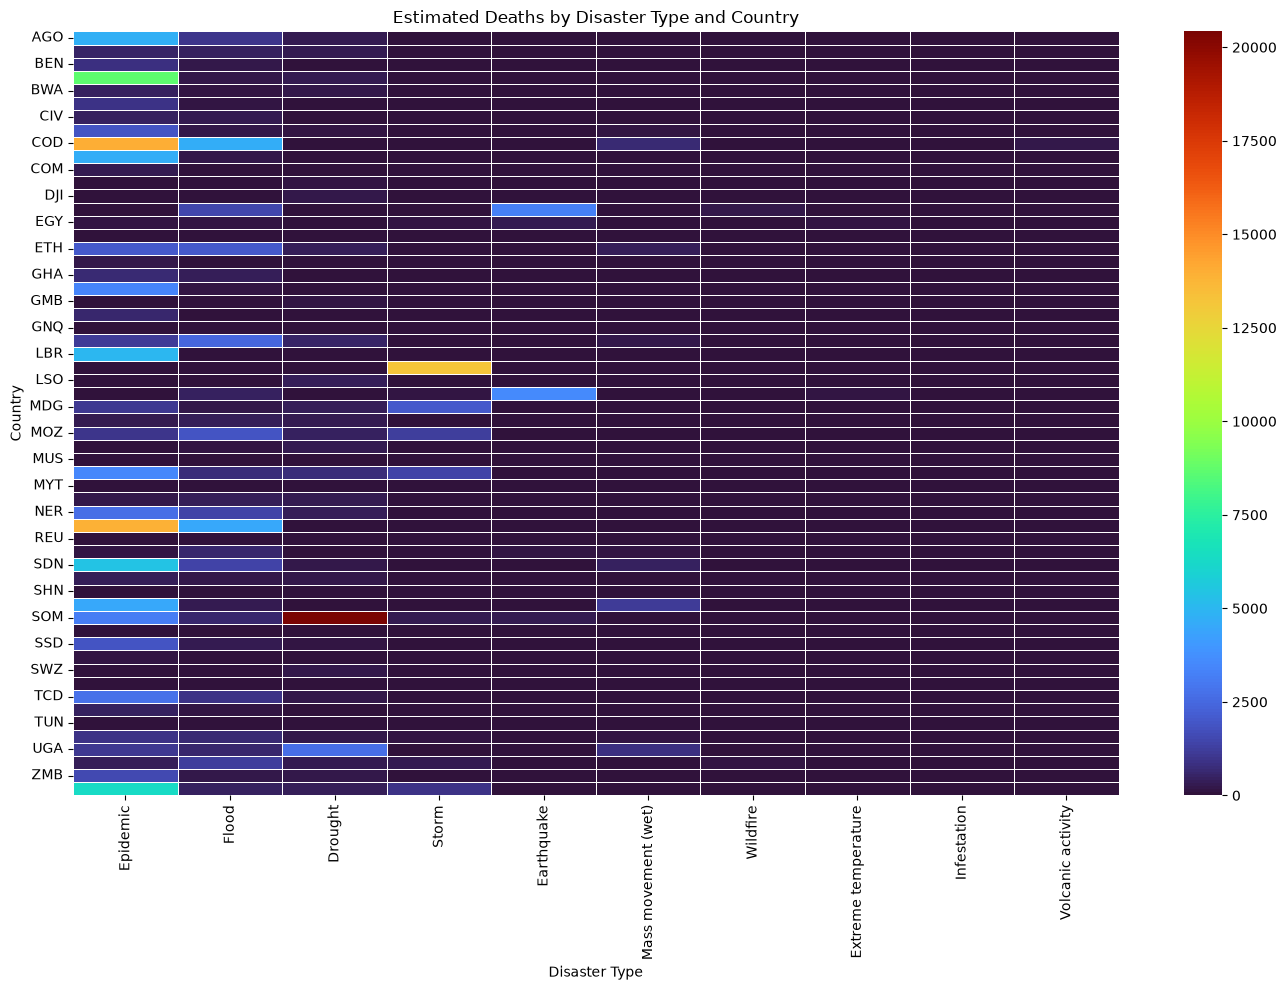

In [183]:
plt.figure(figsize=(14, 10))

sns.heatmap( pivot_df,   cmap='turbo', linewidths=0.5)
plt.title('Estimated Deaths by Disaster Type and Country')
plt.xlabel('Disaster Type')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

## **Data preparation**

## **Modeling**

## **Evaluation**